In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Day 14 libraries imported successfully.")

Day 14 libraries imported successfully.


In [2]:
day14_input_path = Path(
    "../data/analysis_data/APL_Day5_Delay_Risk_Analysis.csv"
)

if not day14_input_path.exists():
    raise FileNotFoundError(
        f"Input dataset not found: "
        f"{day14_input_path.resolve()}"
    )

df_day14_source = pd.read_csv(
    day14_input_path,
    encoding="cp1252",
    low_memory=False
)

df_day14 = df_day14_source.copy()

print("Day 14 source dataset loaded successfully.")
print("Dataset shape:", df_day14.shape)

display(df_day14.head())

Day 14 source dataset loaded successfully.
Dataset shape: (180519, 56)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Fname,Customer Id,Customer Lname,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,Order Item Discount,Order Item Discount Rate,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Product Name,Product Price,Shipping Mode,Shipping_Delay_Days,Is_Delayed,Is_On_Time,Early_Delivery_Days,Delay_Severity,Delivery_Efficiency_Ratio,Revenue_Per_Unit,Profit_Margin,Discount_Level,Region_Market,Shipping_Mode_Rank,Is_Corporate_Customer,Order_Quantity_Category,Operational_Risk_Profile,Delivery_Status,Risk_Status
0,DEBIT,6,4,159.69,472.45,Late delivery,1,9,Cardio Equipment,Brownsville,EE. UU.,Richard,1,Hernandez,Consumer,TX,6303 Heather Plaza,78521.0,3,Footwear,25.953648,-97.507683,Pacific Asia,Mumbai,India,1,27.50,0.06,99.99,0.34,5,499.95,472.45,159.69,South Asia,Maharashtra,COMPLETE,Nike Men's Free 5.0+ Running Shoe,99.99,Standard Class,2,1,0,0,Major Delay,0.666667,99.99,0.319412,Low Discount,Pacific Asia - South Asia,4,0,Large,High Risk - Slower Shipping,Delayed,High Risk
1,DEBIT,4,4,48.71,167.96,Shipping on time,0,29,Shop By Sport,Littleton,EE. UU.,Mary,2,Barrett,Consumer,CO,9526 Noble Embers Ridge,80126.0,5,Golf,38.375595,-104.726021,LATAM,San Pedro Sula,Honduras,2,31.99,0.16,39.99,0.29,5,199.95,167.96,48.71,Central America,Cortés,ON_HOLD,Under Armour Girls' Toddler Spine Surge Runni,39.99,Standard Class,0,0,1,0,On Time / Early,1.000000,39.99,0.243611,Medium Discount,LATAM - Central America,4,0,Large,Lower Risk,On Time,Low Risk
2,DEBIT,4,4,87.36,181.99,Shipping on time,0,48,Water Sports,Littleton,EE. UU.,Mary,2,Barrett,Consumer,CO,9526 Noble Embers Ridge,80126.0,7,Fan Shop,38.375595,-104.726021,LATAM,San Pedro Sula,Honduras,2,18.00,0.09,199.99,0.48,1,199.99,181.99,87.36,Central America,Cortés,ON_HOLD,Pelican Sunstream 100 Kayak,199.99,Standard Class,0,0,1,0,On Time / Early,1.000000,199.99,0.436822,Low Discount,LATAM - Central America,4,0,Small,Lower Risk,On Time,Low Risk
3,DEBIT,6,4,-41.89,175.99,Late delivery,1,48,Water Sports,Littleton,EE. UU.,Mary,2,Barrett,Consumer,CO,9526 Noble Embers Ridge,80126.0,7,Fan Shop,38.375595,-104.726021,USCA,New York City,Estados Unidos,2,24.00,0.12,199.99,-0.24,1,199.99,175.99,-41.89,East of USA,Nueva York,COMPLETE,Pelican Sunstream 100 Kayak,199.99,Standard Class,2,1,0,0,Major Delay,0.666667,199.99,-0.209460,Medium Discount,USCA - East of USA,4,0,Small,High Risk - Slower Shipping,Delayed,High Risk
4,DEBIT,6,4,10.00,40.00,Late delivery,1,24,Women's Apparel,Littleton,EE. UU.,Mary,2,Barrett,Consumer,CO,9526 Noble Embers Ridge,80126.0,5,Golf,38.375595,-104.726021,USCA,New York City,Estados Unidos,2,10.00,0.20,50.00,0.25,1,50.00,40.00,10.00,East of USA,Nueva York,COMPLETE,Nike Men's Dri-FIT Victory Golf Polo,50.00,Standard Class,2,1,0,0,Major Delay,0.666667,50.00,0.200000,Medium Discount,USCA - East of USA,4,0,Small,High Risk - Slower Shipping,Delayed,High Risk


## Dataset Overview & Validation

In [3]:
required_columns = [
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Shipping_Delay_Days",
    "Is_Delayed",
    "Late_delivery_risk",
    "Delay_Severity",
    "Shipping Mode",
    "Order Item Quantity",
    "Order Item Product Price",
    "Sales",
    "Order Item Total",
    "Order Profit Per Order",
    "Order Item Profit Ratio",
    "Profit_Margin",
    "Order Item Discount",
    "Order Item Discount Rate",
    "Discount_Level",
    "Operational_Risk_Profile",
    "Delivery_Status"
]

missing_columns = [
    col for col in required_columns
    if col not in df_day14.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

print("All required relationship analysis columns are available.")

print("Total records:", len(df_day14))
print("Total columns:", len(df_day14.columns))
print("Duplicate rows:", df_day14.duplicated().sum())

display(
    df_day14[required_columns]
    .isna()
    .sum()
    .to_frame(name="Missing_Values")
    .sort_values("Missing_Values", ascending=False)
)

All required relationship analysis columns are available.
Total records: 180519
Total columns: 56
Duplicate rows: 0


,Missing_Values
Days for shipping (real),0
Days for shipment (scheduled),0
Shipping_Delay_Days,0
Is_Delayed,0
Late_delivery_risk,0
Delay_Severity,0
Shipping Mode,0
Order Item Quantity,0
Order Item Product Price,0
Sales,0


## Prepare Relationship Analysis Variables

In [4]:
numeric_columns = [
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Shipping_Delay_Days",
    "Order Item Quantity",
    "Order Item Product Price",
    "Sales",
    "Order Item Total",
    "Order Profit Per Order",
    "Order Item Profit Ratio",
    "Profit_Margin",
    "Order Item Discount",
    "Order Item Discount Rate",
    "Is_Delayed",
    "Late_delivery_risk"
]

categorical_columns = [
    "Shipping Mode",
    "Delay_Severity",
    "Discount_Level",
    "Operational_Risk_Profile",
    "Delivery_Status"
]

for col in numeric_columns:
    df_day14[col] = pd.to_numeric(
        df_day14[col],
        errors="coerce"
    )

for col in categorical_columns:
    df_day14[col] = (
        df_day14[col]
        .astype("string")
        .str.strip()
    )

print("Relationship analysis variables prepared successfully.")

display(
    df_day14[numeric_columns]
    .describe()
    .T
)

Relationship analysis variables prepared successfully.


,count,mean,std,min,25%,50%,75%,max
Days for shipping (real),180519.0,3.497654,1.623722,0.00,2.00000,3.000000,5.000000,6.000000
Days for shipment (scheduled),180519.0,2.931847,1.374449,0.00,2.00000,4.000000,4.000000,4.000000
Shipping_Delay_Days,180519.0,0.565807,1.490966,-2.00,0.00000,1.000000,1.000000,4.000000
Order Item Quantity,180519.0,2.127638,1.453451,1.00,1.00000,1.000000,3.000000,5.000000
Order Item Product Price,180519.0,141.232547,139.732489,9.99,50.00000,59.990000,199.990000,1999.990000
Sales,180519.0,203.772092,132.273075,9.99,119.98000,199.920000,299.950000,1999.990000
Order Item Total,180519.0,183.107607,120.043668,7.49,104.38000,163.990000,247.400000,1939.990000
Order Profit Per Order,180519.0,21.974989,104.433526,-4274.98,7.00000,31.520000,64.800000,911.800000
Order Item Profit Ratio,180519.0,0.120647,0.466796,-2.75,0.08000,0.270000,0.360000,0.500000
Profit_Margin,180519.0,0.108326,0.420594,-2.75,0.06224,0.242512,0.336014,0.500443


## Numerical Correlation Analysis

In [5]:
correlation_columns = [
    "Days for shipping (real)",
    "Days for shipment (scheduled)",
    "Shipping_Delay_Days",
    "Order Item Quantity",
    "Order Item Product Price",
    "Sales",
    "Order Item Total",
    "Order Profit Per Order",
    "Order Item Profit Ratio",
    "Profit_Margin",
    "Order Item Discount",
    "Order Item Discount Rate",
    "Is_Delayed",
    "Late_delivery_risk"
]

correlation_matrix = (
    df_day14[correlation_columns]
    .corr(method="pearson")
)

display(
    correlation_matrix.round(3)
)

,Days for shipping (real),Days for shipment (scheduled),Shipping_Delay_Days,Order Item Quantity,Order Item Product Price,Sales,Order Item Total,Order Profit Per Order,Order Item Profit Ratio,Profit_Margin,Order Item Discount,Order Item Discount Rate,Is_Delayed,Late_delivery_risk
Days for shipping (real),1.000,0.516,0.613,-0.001,0.002,0.002,0.002,-0.005,-0.005,-0.005,0.002,0.001,0.420,0.401
Days for shipment (scheduled),0.516,1.000,-0.360,-0.003,0.007,0.006,0.006,-0.000,-0.002,-0.002,0.003,0.000,-0.389,-0.369
Shipping_Delay_Days,0.613,-0.360,1.000,0.002,-0.004,-0.004,-0.004,-0.005,-0.003,-0.003,-0.000,0.002,0.816,0.778
Order Item Quantity,-0.001,-0.003,0.002,1.000,-0.476,0.106,0.105,0.016,0.001,0.001,0.065,-0.000,0.000,-0.000
Order Item Product Price,0.002,0.007,-0.004,-0.476,1.000,0.790,0.782,0.103,-0.002,-0.002,0.488,0.000,-0.002,-0.002
Sales,0.002,0.006,-0.004,0.106,0.790,1.000,0.990,0.132,-0.002,-0.002,0.617,0.000,-0.004,-0.004
Order Item Total,0.002,0.006,-0.004,0.105,0.782,0.990,1.000,0.133,-0.001,0.001,0.499,-0.119,-0.004,-0.004
Order Profit Per Order,-0.005,-0.000,-0.005,0.016,0.103,0.132,0.133,1.000,0.824,0.826,0.065,-0.019,-0.004,-0.004
Order Item Profit Ratio,-0.005,-0.002,-0.003,0.001,-0.002,-0.002,-0.001,0.824,1.000,0.997,-0.003,-0.003,-0.003,-0.002
Profit_Margin,-0.005,-0.002,-0.003,0.001,-0.002,-0.002,0.001,0.826,0.997,1.000,-0.016,-0.023,-0.003,-0.003


## Visualize the Correlation Matrix

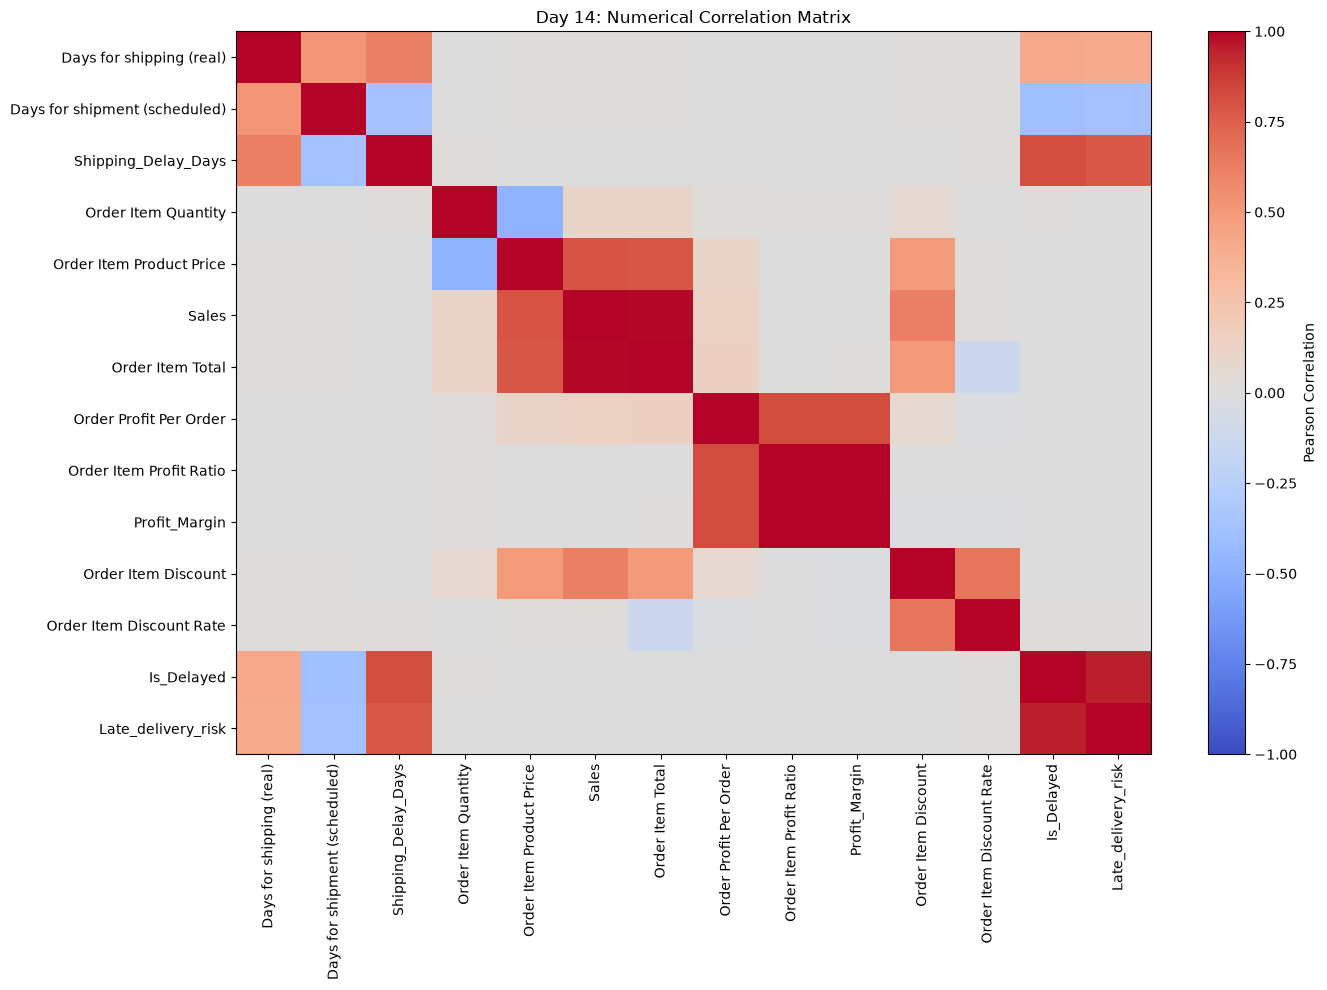

In [6]:
plt.figure(figsize=(14, 10))

image = plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    aspect="auto"
)

plt.colorbar(
    image,
    label="Pearson Correlation"
)

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation_matrix.index)),
    correlation_matrix.index
)

plt.title("Day 14: Numerical Correlation Matrix")

plt.tight_layout()
plt.show()

## Shipping Delay and Financial Relationships

In [7]:
delay_financial_relationship = (
    df_day14
    .groupby(
        "Delay_Severity",
        observed=True,
        dropna=False
    )
    .agg(
        Shipment_Records=("Delay_Severity", "size"),
        Average_Delay_Days=("Shipping_Delay_Days", "mean"),
        Average_Sales=("Sales", "mean"),
        Total_Sales=("Sales", "sum"),
        Average_Order_Profit=("Order Profit Per Order", "mean"),
        Total_Order_Profit=("Order Profit Per Order", "sum"),
        Average_Profit_Margin=("Profit_Margin", "mean")
    )
    .reset_index()
)

display(
    delay_financial_relationship.round(3)
)

,Delay_Severity,Shipment_Records,Average_Delay_Days,Average_Sales,Total_Sales,Average_Order_Profit,Total_Order_Profit,Average_Profit_Margin
0,Major Delay,42753,2.492,203.405,8696167.32,21.082,901336.20,0.106
1,Minor Delay,60647,1.000,203.291,12329017.44,21.941,1330630.45,0.108
2,On Time / Early,77119,-0.843,204.354,15759549.55,22.497,1734936.32,0.110


## Discount and Profitability Relationships

In [8]:
discount_profit_relationship = (
    df_day14
    .groupby(
        "Discount_Level",
        observed=True,
        dropna=False
    )
    .agg(
        Shipment_Records=("Discount_Level", "size"),
        Average_Discount_Rate=("Order Item Discount Rate", "mean"),
        Average_Sales=("Sales", "mean"),
        Average_Order_Profit=("Order Profit Per Order", "mean"),
        Total_Order_Profit=("Order Profit Per Order", "sum"),
        Average_Profit_Margin=("Profit_Margin", "mean")
    )
    .reset_index()
)

display(
    discount_profit_relationship.round(3)
)

,Discount_Level,Shipment_Records,Average_Discount_Rate,Average_Sales,Average_Order_Profit,Total_Order_Profit,Average_Profit_Margin
0,High Discount,10029,0.250,203.841,19.134,191896.72,0.095
1,Low Discount,90259,0.052,203.743,23.246,2098193.71,0.115
2,Medium Discount,70203,0.159,203.815,20.076,1409400.14,0.099
3,No Discount,10028,0.000,203.667,26.667,267412.40,0.127


### Visualize average profit margin

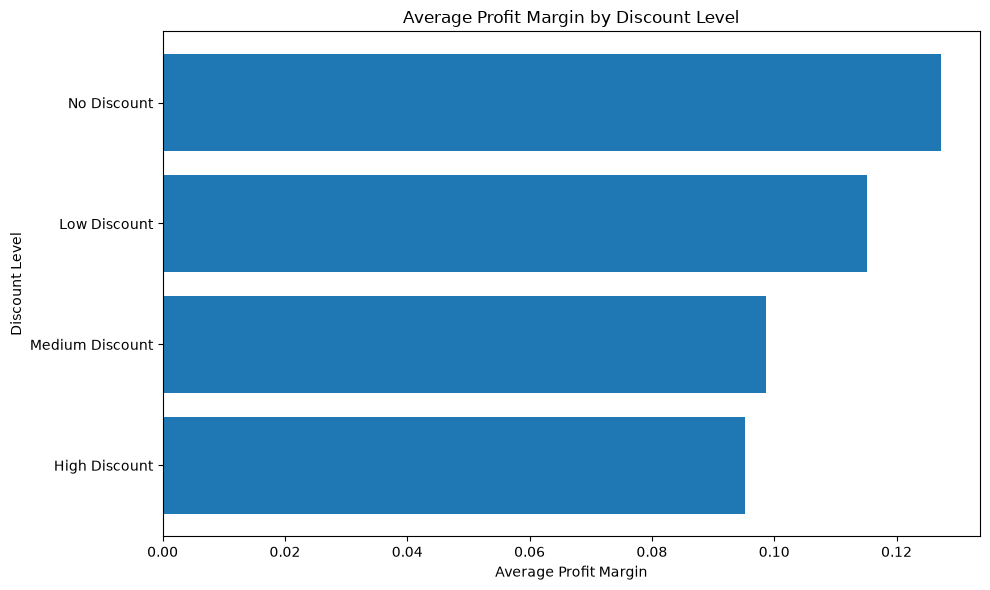

In [9]:
discount_chart_data = (
    discount_profit_relationship
    .dropna(subset=["Discount_Level"])
    .sort_values("Average_Profit_Margin")
)

plt.figure(figsize=(10, 6))

plt.barh(
    discount_chart_data["Discount_Level"].astype(str),
    discount_chart_data["Average_Profit_Margin"]
)

plt.title("Average Profit Margin by Discount Level")
plt.xlabel("Average Profit Margin")
plt.ylabel("Discount Level")

plt.tight_layout()
plt.show()

## Order Quantity, Product Price, Sales and Profit Relationships 

In [10]:
quantity_financial_relationship = (
    df_day14
    .groupby(
        "Order Item Quantity",
        dropna=False
    )
    .agg(
        Shipment_Records=("Order Item Quantity", "size"),
        Average_Product_Price=("Order Item Product Price", "mean"),
        Average_Sales=("Sales", "mean"),
        Average_Order_Item_Total=("Order Item Total", "mean"),
        Average_Order_Profit=("Order Profit Per Order", "mean"),
        Average_Profit_Margin=("Profit_Margin", "mean")
    )
    .reset_index()
    .sort_values("Order Item Quantity")
)

display(
    quantity_financial_relationship.round(3)
)

,Order Item Quantity,Shipment_Records,Average_Product_Price,Average_Sales,Average_Order_Item_Total,Average_Order_Profit,Average_Profit_Margin
0,1,99134,211.665,211.665,190.195,22.667,0.107
1,2,20315,55.295,110.590,99.395,12.239,0.110
2,3,20350,55.564,166.692,149.779,18.150,0.109
3,4,20335,55.424,221.695,199.221,24.162,0.110
4,5,20385,55.478,277.391,249.262,29.948,0.108


### Visualize quantity against average sales

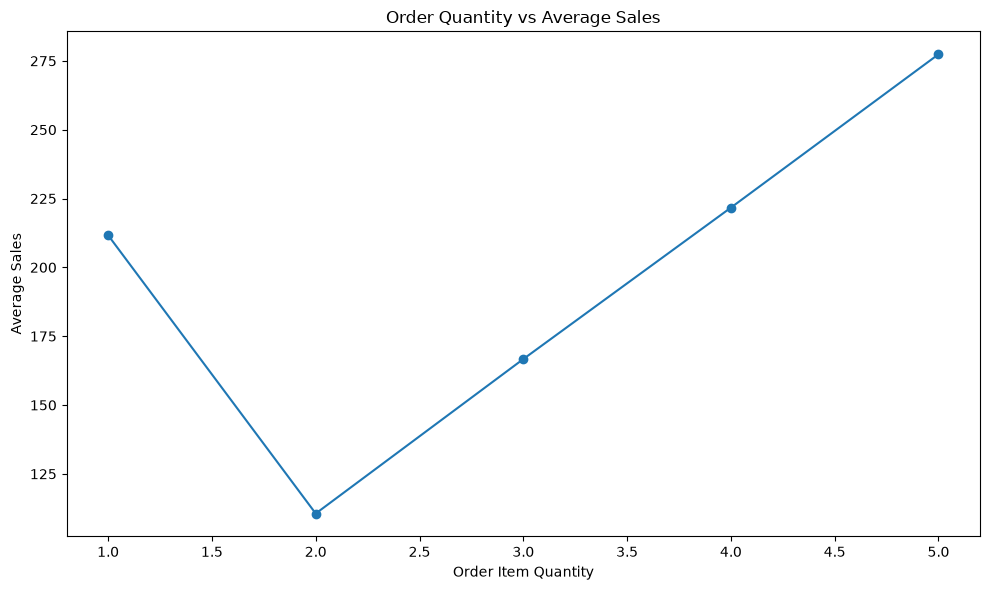

In [11]:
quantity_chart_data = (
    quantity_financial_relationship
    .dropna(
        subset=[
            "Order Item Quantity",
            "Average_Sales"
        ]
    )
    .sort_values("Order Item Quantity")
)

plt.figure(figsize=(10, 6))

plt.plot(
    quantity_chart_data["Order Item Quantity"],
    quantity_chart_data["Average_Sales"],
    marker="o"
)

plt.title("Order Quantity vs Average Sales")
plt.xlabel("Order Item Quantity")
plt.ylabel("Average Sales")

plt.tight_layout()
plt.show()

## Shipping Mode and Delivery Relationships

In [12]:
shipping_mode_relationship = (
    df_day14
    .groupby(
        "Shipping Mode",
        observed=True,
        dropna=False
    )
    .agg(
        Total_Shipments=("Shipping Mode", "size"),
        Delayed_Shipments=("Is_Delayed", "sum"),
        Average_Shipping_Delay_Days=("Shipping_Delay_Days", "mean"),
        Average_Actual_Shipping_Days=("Days for shipping (real)", "mean"),
        Average_Scheduled_Shipping_Days=(
            "Days for shipment (scheduled)",
            "mean"
        )
    )
    .reset_index()
)

shipping_mode_relationship["Delay_Rate_%"] = (
    shipping_mode_relationship["Delayed_Shipments"]
    .div(shipping_mode_relationship["Total_Shipments"])
    .mul(100)
)

display(
    shipping_mode_relationship
    .sort_values("Delay_Rate_%", ascending=False)
    .round(3)
)

,Shipping Mode,Total_Shipments,Delayed_Shipments,Average_Shipping_Delay_Days,Average_Actual_Shipping_Days,Average_Scheduled_Shipping_Days,Delay_Rate_%
0,First Class,27814,27814,1.000,2.000,1.0,100.0
2,Second Class,35216,28078,1.991,3.991,2.0,79.731
1,Same Day,9737,4657,0.478,0.478,0.0,47.828
3,Standard Class,107752,42851,-0.004,3.996,4.0,39.768


### Visuaize delay rates by shipping mode

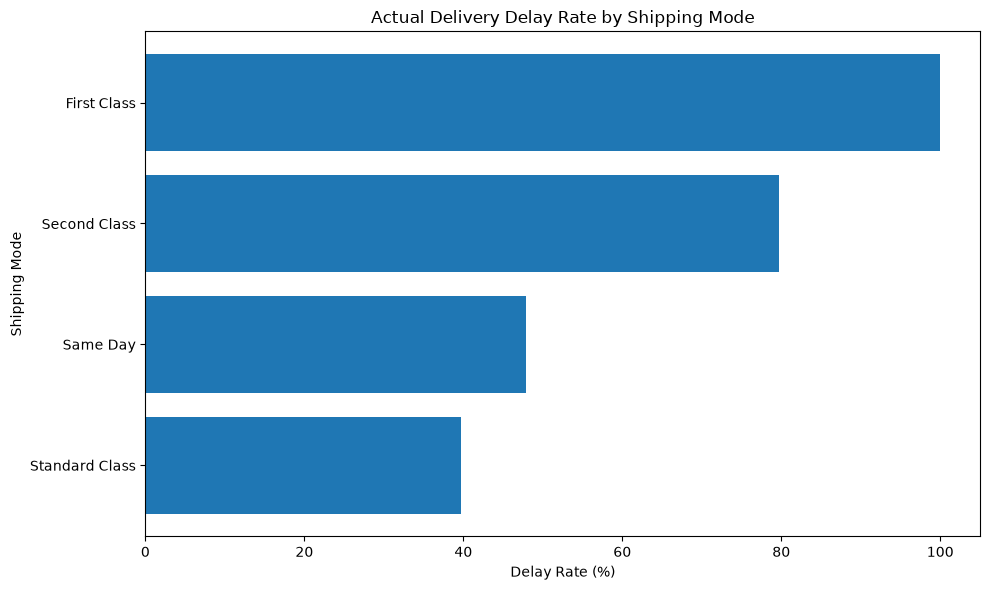

In [13]:
shipping_mode_chart = (
    shipping_mode_relationship
    .dropna(subset=["Shipping Mode", "Delay_Rate_%"])
    .sort_values("Delay_Rate_%")
)

plt.figure(figsize=(10, 6))

plt.barh(
    shipping_mode_chart["Shipping Mode"].astype(str),
    shipping_mode_chart["Delay_Rate_%"]
)

plt.title("Actual Delivery Delay Rate by Shipping Mode")
plt.xlabel("Delay Rate (%)")
plt.ylabel("Shipping Mode")

plt.tight_layout()
plt.show()

## Operational Risk & Delivery Relationships

In [15]:
risk_delivery_counts = pd.crosstab(
    df_day14["Operational_Risk_Profile"],
    df_day14["Delivery_Status"],
    dropna=False
)

display(risk_delivery_counts)

Delivery_Status,Delayed,Early,On Time
Operational_Risk_Profile,,,
High Risk,30967,0,0
High Risk - Slower Shipping,68010,0,0
Lower Risk,4423,43366,33753


### Calculate delivery-status percentages 

In [16]:
risk_delivery_percentages = (
    pd.crosstab(
        df_day14["Operational_Risk_Profile"],
        df_day14["Delivery_Status"],
        normalize="index",
        dropna=False
    )
    .mul(100)
)

display(
    risk_delivery_percentages.round(2)
)

Delivery_Status,Delayed,Early,On Time
Operational_Risk_Profile,,,
High Risk,100.00,0.00,0.00
High Risk - Slower Shipping,100.00,0.00,0.00
Lower Risk,5.42,53.18,41.39


### Visualize delivery-status percentages

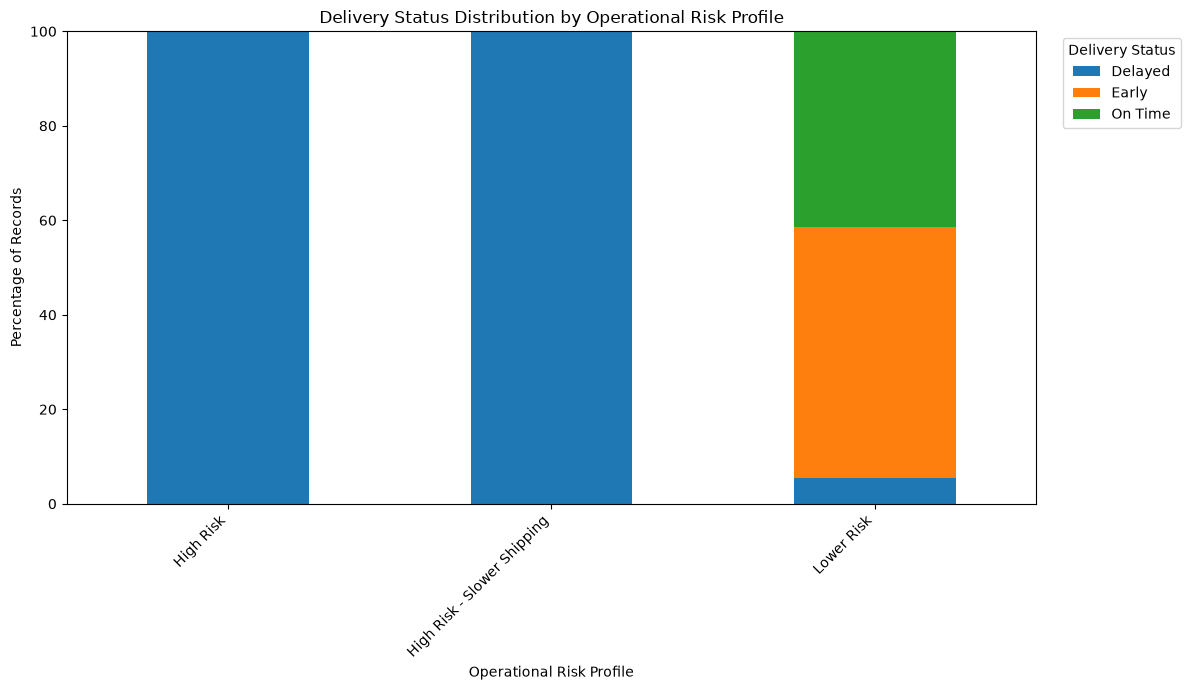

In [17]:
risk_delivery_percentages.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 7)
)

plt.title(
    "Delivery Status Distribution by Operational Risk Profile"
)

plt.xlabel("Operational Risk Profile")
plt.ylabel("Percentage of Records")
plt.xticks(rotation=45, ha="right")

plt.legend(
    title="Delivery Status",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

## Additional Relationship: Actual vs Scheduled Shipping Duration

In [18]:
shipping_duration_relationship = (
    df_day14
    .groupby(
        "Shipping Mode",
        observed=True,
        dropna=False
    )
    .agg(
        Total_Shipments=("Shipping Mode", "size"),
        Average_Actual_Days=("Days for shipping (real)", "mean"),
        Average_Scheduled_Days=(
            "Days for shipment (scheduled)",
            "mean"
        ),
        Average_Delay_Days=("Shipping_Delay_Days", "mean")
    )
    .reset_index()
)

shipping_duration_relationship["Average_Duration_Gap"] = (
    shipping_duration_relationship["Average_Actual_Days"]
    - shipping_duration_relationship["Average_Scheduled_Days"]
)

display(
    shipping_duration_relationship.round(3)
)

,Shipping Mode,Total_Shipments,Average_Actual_Days,Average_Scheduled_Days,Average_Delay_Days,Average_Duration_Gap
0,First Class,27814,2.000,1.0,1.000,1.000
1,Same Day,9737,0.478,0.0,0.478,0.478
2,Second Class,35216,3.991,2.0,1.991,1.991
3,Standard Class,107752,3.996,4.0,-0.004,-0.004


## Day 14 KPI Summary

In [19]:
overall_delay_rate = (
    df_day14["Is_Delayed"].mean() * 100
)

overall_average_delay_days = (
    df_day14["Shipping_Delay_Days"].mean()
)

overall_average_profit = (
    df_day14["Order Profit Per Order"].mean()
)

overall_average_profit_margin = (
    df_day14["Profit_Margin"].mean()
)

highest_delay_mode_row = (
    shipping_mode_relationship
    .dropna(subset=["Delay_Rate_%"])
    .sort_values(
        ["Delay_Rate_%", "Total_Shipments"],
        ascending=[False, False]
    )
    .head(1)
)

highest_delay_mode = (
    highest_delay_mode_row["Shipping Mode"].iloc[0]
    if not highest_delay_mode_row.empty
    else "Unavailable"
)

highest_delay_mode_rate = (
    highest_delay_mode_row["Delay_Rate_%"].iloc[0]
    if not highest_delay_mode_row.empty
    else np.nan
)

lowest_profit_margin_discount_row = (
    discount_profit_relationship
    .dropna(subset=["Average_Profit_Margin"])
    .sort_values("Average_Profit_Margin")
    .head(1)
)

lowest_profit_margin_discount = (
    lowest_profit_margin_discount_row["Discount_Level"].iloc[0]
    if not lowest_profit_margin_discount_row.empty
    else "Unavailable"
)

lowest_profit_margin_value = (
    lowest_profit_margin_discount_row[
        "Average_Profit_Margin"
    ].iloc[0]
    if not lowest_profit_margin_discount_row.empty
    else np.nan
)

day14_kpis = pd.DataFrame({
    "Metric": [
        "Total Shipment Records",
        "Overall Actual Delay Rate (%)",
        "Average Shipping Delay Days",
        "Average Recorded Order Profit",
        "Average Profit Margin",
        "Shipping Mode with Highest Delay Rate",
        "Highest Shipping Mode Delay Rate (%)",
        "Discount Level with Lowest Average Profit Margin",
        "Lowest Average Profit Margin"
    ],

    "Value": [
        len(df_day14),
        overall_delay_rate,
        overall_average_delay_days,
        overall_average_profit,
        overall_average_profit_margin,
        highest_delay_mode,
        highest_delay_mode_rate,
        lowest_profit_margin_discount,
        lowest_profit_margin_value
    ]
})

display(day14_kpis.round(3))

,Metric,Value
0,Total Shipment Records,180519
1,Overall Actual Delay Rate (%),57.279289
2,Average Shipping Delay Days,0.565807
3,Average Recorded Order Profit,21.974989
4,Average Profit Margin,0.108326
5,Shipping Mode with Highest Delay Rate,First Class
6,Highest Shipping Mode Delay Rate (%),100.0
7,Discount Level with Lowest Average Profit Margin,High Discount
8,Lowest Average Profit Margin,0.095222


## Saving Day 14 Analytical Outputs

In [20]:
day14_output_dir = Path(
    "../data/analysis_data/"
)

if not day14_output_dir.exists():
    raise FileNotFoundError(
        f"Output directory does not exist: "
        f"{day14_output_dir.resolve()}"
    )

day14_outputs = {
    "APL_Day14_Correlation_Matrix.csv":
        correlation_matrix.reset_index(),

    "APL_Day14_Delay_Financial_Relationship.csv":
        delay_financial_relationship,

    "APL_Day14_Discount_Profit_Relationship.csv":
        discount_profit_relationship,

    "APL_Day14_Quantity_Financial_Relationship.csv":
        quantity_financial_relationship,

    "APL_Day14_Shipping_Mode_Relationship.csv":
        shipping_mode_relationship,

    "APL_Day14_Risk_Delivery_Counts.csv":
        risk_delivery_counts.reset_index(),

    "APL_Day14_Risk_Delivery_Percentages.csv":
        risk_delivery_percentages.reset_index(),

    "APL_Day14_Shipping_Duration_Relationship.csv":
        shipping_duration_relationship,

    "APL_Day14_Relationship_KPIs.csv":
        day14_kpis
}

for filename, output_df in day14_outputs.items():

    output_path = day14_output_dir / filename

    output_df.to_csv(
        output_path,
        index=False,
        encoding="utf-8-sig"
    )

    print("Saved:", output_path.resolve())

print("All Day 14 analytical outputs saved successfully.")

Saved: D:\Data Analytics Project\Delivery Performance, Delay Risk, and Logistics Efficiency Analysis in Global Supply Chain Operations\data\analysis_data\APL_Day14_Correlation_Matrix.csv
Saved: D:\Data Analytics Project\Delivery Performance, Delay Risk, and Logistics Efficiency Analysis in Global Supply Chain Operations\data\analysis_data\APL_Day14_Delay_Financial_Relationship.csv
Saved: D:\Data Analytics Project\Delivery Performance, Delay Risk, and Logistics Efficiency Analysis in Global Supply Chain Operations\data\analysis_data\APL_Day14_Discount_Profit_Relationship.csv
Saved: D:\Data Analytics Project\Delivery Performance, Delay Risk, and Logistics Efficiency Analysis in Global Supply Chain Operations\data\analysis_data\APL_Day14_Quantity_Financial_Relationship.csv
Saved: D:\Data Analytics Project\Delivery Performance, Delay Risk, and Logistics Efficiency Analysis in Global Supply Chain Operations\data\analysis_data\APL_Day14_Shipping_Mode_Relationship.csv
Saved: D:\Data Analytics

## Validating Day 14

In [21]:
day14_validation_checks = {
    "Source Dataset Loaded":
        len(df_day14) > 0,

    "Required Columns Available":
        len(missing_columns) == 0,

    "Correlation Matrix Not Empty":
        not correlation_matrix.empty,

    "Correlation Values Within Bounds":
        (
            correlation_matrix.min().min() >= -1 - 1e-9
            and correlation_matrix.max().max() <= 1 + 1e-9
        ),

    "Delay Financial Analysis Not Empty":
        not delay_financial_relationship.empty,

    "Discount Profit Analysis Not Empty":
        not discount_profit_relationship.empty,

    "Quantity Financial Analysis Not Empty":
        not quantity_financial_relationship.empty,

    "Shipping Mode Analysis Not Empty":
        not shipping_mode_relationship.empty,

    "Risk Delivery Analysis Not Empty":
        not risk_delivery_percentages.empty,

    "KPI Summary Not Empty":
        not day14_kpis.empty,

    "All Analytical Output Files Exist":
        all(
            (day14_output_dir / filename).exists()
            for filename in day14_outputs
        )
}

day14_validation_report = pd.DataFrame({
    "Validation_Check": list(day14_validation_checks.keys()),

    "Status": [
        "PASS" if result else "FAIL"
        for result in day14_validation_checks.values()
    ]
})

display(day14_validation_report)

if all(day14_validation_checks.values()):
    print("ALL DAY 14 VALIDATION CHECKS PASSED.")
else:
    print("SOME DAY 14 VALIDATION CHECKS FAILED.")

    display(
        day14_validation_report[
            day14_validation_report["Status"] == "FAIL"
        ]
    )

,Validation_Check,Status
0,Source Dataset Loaded,PASS
1,Required Columns Available,PASS
2,Correlation Matrix Not Empty,PASS
3,Correlation Values Within Bounds,PASS
4,Delay Financial Analysis Not Empty,PASS
5,Discount Profit Analysis Not Empty,PASS
6,Quantity Financial Analysis Not Empty,PASS
7,Shipping Mode Analysis Not Empty,PASS
8,Risk Delivery Analysis Not Empty,PASS
9,KPI Summary Not Empty,PASS


ALL DAY 14 VALIDATION CHECKS PASSED.
